In [1]:
import zipfile
import os

zip_path = "/content/archive (3).zip"
extract_path = "/content/UNSW_NB15"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [2]:
import os

for root, dirs, files in os.walk("/content/UNSW_NB15"):
    print("Folder:", root)
    for file in files:
        print("   ", file)

Folder: /content/UNSW_NB15
    UNSW_NB15_training-set.parquet
    UNSW_NB15_testing-set.parquet


In [3]:
import pandas as pd

train_path = "/content/UNSW_NB15/UNSW_NB15_training-set.parquet"
test_path = "/content/UNSW_NB15/UNSW_NB15_testing-set.parquet"

train_df = pd.read_parquet(train_path)
test_df = pd.read_parquet(test_path)

print("Training data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)

Training data shape: (175341, 36)
Testing data shape: (82332, 36)


In [4]:
print("Columns in the dataset:")
print(train_df.columns.tolist())

Columns in the dataset:
['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'is_sm_ips_ports', 'attack_cat', 'label']


In [5]:
train_df.head()

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,...,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,14158.942383,...,0,0,1,1,0,0,0,0,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8395.112305,...,0,0,1,1,0,0,0,0,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1572.271851,...,0,0,1,1,0,0,0,0,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,2740.178955,...,0,0,1,1,1,1,0,0,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,8561.499023,...,0,0,2,1,0,0,0,0,Normal,0


In [6]:
print(train_df["label"].value_counts())

label
1    119341
0     56000
Name: count, dtype: int64


In [7]:
import pandas as pd

train_path = "/content/UNSW_NB15/UNSW_NB15_training-set.parquet"
test_path = "/content/UNSW_NB15/UNSW_NB15_testing-set.parquet"

train_df = pd.read_parquet(train_path)
test_df = pd.read_parquet(test_path)

print("Training data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)

Training data shape: (175341, 36)
Testing data shape: (82332, 36)


In [8]:
print("Training columns:")
print(train_df.columns.tolist())

Training columns:
['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'is_sm_ips_ports', 'attack_cat', 'label']


In [9]:
train_df.head()

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,...,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,14158.942383,...,0,0,1,1,0,0,0,0,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8395.112305,...,0,0,1,1,0,0,0,0,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1572.271851,...,0,0,1,1,0,0,0,0,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,2740.178955,...,0,0,1,1,1,1,0,0,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,8561.499023,...,0,0,2,1,0,0,0,0,Normal,0


In [10]:
print(train_df["label"].value_counts())

label
1    119341
0     56000
Name: count, dtype: int64


In [11]:
print(train_df["attack_cat"].value_counts())

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [12]:
print("Training rows and columns:", train_df.shape)
print("Testing rows and columns:", test_df.shape)

print("\nMissing values:")
print(train_df.isnull().sum().sort_values(ascending=False).head(15))

print("\nDuplicate rows:", train_df.duplicated().sum())

Training rows and columns: (175341, 36)
Testing rows and columns: (82332, 36)

Missing values:
dur        0
proto      0
service    0
state      0
spkts      0
dpkts      0
sbytes     0
dbytes     0
rate       0
sload      0
dload      0
sloss      0
dloss      0
sinpkt     0
dinpkt     0
dtype: int64

Duplicate rows: 78519


label
1    119341
0     56000
Name: count, dtype: int64


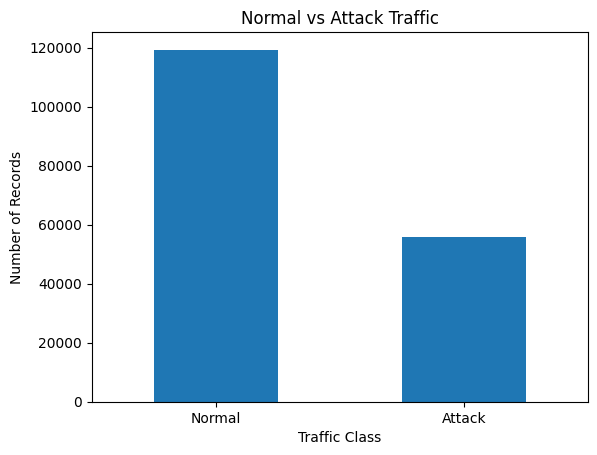

In [13]:
import matplotlib.pyplot as plt

print(train_df["label"].value_counts())

train_df["label"].value_counts().plot(kind="bar")

plt.title("Normal vs Attack Traffic")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["Normal", "Attack"], rotation=0)
plt.show()

In [14]:
print(train_df["attack_cat"].value_counts())

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


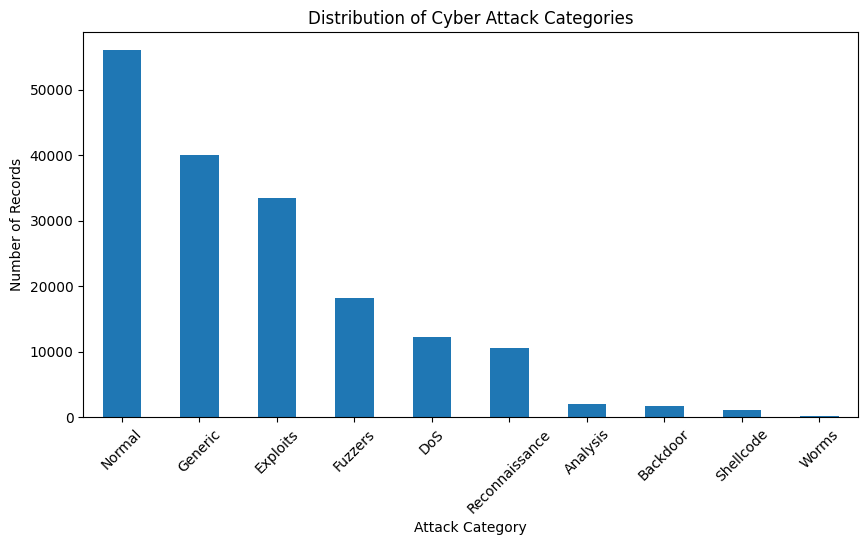

In [15]:
train_df["attack_cat"].value_counts().plot(kind="bar", figsize=(10,5))

plt.title("Distribution of Cyber Attack Categories")
plt.xlabel("Attack Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.show()

In [16]:
X_train = train_df.drop(columns=["label", "attack_cat"])
y_train = train_df["label"]

X_test = test_df.drop(columns=["label", "attack_cat"])
y_test = test_df["label"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (175341, 34)
y_train: (175341,)
X_test: (82332, 34)
y_test: (82332,)


In [17]:
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["int64", "int32", "float64", "float32"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumber of categorical features:", len(categorical_features))

print("\nNumber of numerical features:", len(numerical_features))

Categorical features:
['proto', 'service', 'state']

Number of categorical features: 3

Number of numerical features: 16


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [19]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

Processed training data shape: (175341, 171)
Processed testing data shape: (82332, 171)


In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import time

print("Starting Random Forest training...")

start_time = time.time()

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

training_time = time.time() - start_time

print("Random Forest training completed!")
print(f"Training time: {training_time:.2f} seconds")

Starting Random Forest training...
Random Forest training completed!
Training time: 79.36 seconds


In [21]:
start_time = time.time()

y_pred = rf_model.predict(X_test_processed)

prediction_time = time.time() - start_time

print("Prediction completed!")
print(f"Prediction time: {prediction_time:.2f} seconds")

Prediction completed!
Prediction time: 0.74 seconds


In [22]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 85.86%


In [23]:
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1 Score:  {f1 * 100:.2f}%")

Precision: 80.78%
Recall:    97.52%
F1 Score:  88.37%


In [27]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Attack"],
    zero_division=0
))

              precision    recall  f1-score   support

      Normal       0.96      0.72      0.82     37000
      Attack       0.81      0.98      0.88     45332

    accuracy                           0.86     82332
   macro avg       0.88      0.85      0.85     82332
weighted avg       0.88      0.86      0.85     82332



In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

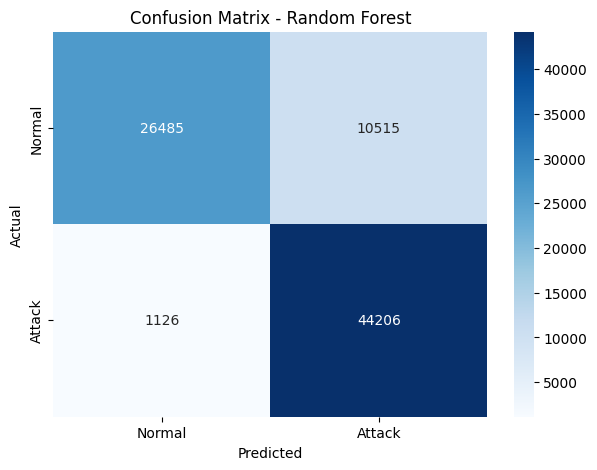

In [30]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Attack"],
    yticklabels=["Normal", "Attack"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")
plt.show()

In [31]:
from sklearn.metrics import confusion_matrix

In [32]:
y_pred = rf_model.predict(X_test_processed)

In [33]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import time

print("Training Decision Tree...")

start_time = time.time()

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=20
)

dt_model.fit(X_train_processed, y_train)

dt_time = time.time() - start_time

dt_pred = dt_model.predict(X_test_processed)

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred, zero_division=0)
dt_recall = recall_score(y_test, dt_pred, zero_division=0)
dt_f1 = f1_score(y_test, dt_pred, zero_division=0)

print("Decision Tree completed!")
print(f"Training time: {dt_time:.2f} seconds")
print(f"Accuracy : {dt_accuracy * 100:.2f}%")
print(f"Precision: {dt_precision * 100:.2f}%")
print(f"Recall   : {dt_recall * 100:.2f}%")
print(f"F1 Score : {dt_f1 * 100:.2f}%")

Training Decision Tree...
Decision Tree completed!
Training time: 5.30 seconds
Accuracy : 86.29%
Precision: 81.80%
Recall   : 96.60%
F1 Score : 88.58%


In [34]:
from sklearn.linear_model import LogisticRegression

print("Training Logistic Regression...")

start_time = time.time()

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_processed, y_train)

lr_time = time.time() - start_time

lr_pred = lr_model.predict(X_test_processed)

lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred, zero_division=0)
lr_recall = recall_score(y_test, lr_pred, zero_division=0)
lr_f1 = f1_score(y_test, lr_pred, zero_division=0)

print("Logistic Regression completed!")
print(f"Training time: {lr_time:.2f} seconds")
print(f"Accuracy : {lr_accuracy * 100:.2f}%")
print(f"Precision: {lr_precision * 100:.2f}%")
print(f"Recall   : {lr_recall * 100:.2f}%")
print(f"F1 Score : {lr_f1 * 100:.2f}%")

Training Logistic Regression...
Logistic Regression completed!
Training time: 19.07 seconds
Accuracy : 70.54%
Precision: 66.11%
Recall   : 95.42%
F1 Score : 78.11%


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [35]:
rf_accuracy = accuracy_score(y_test, y_pred)
rf_precision = precision_score(y_test, y_pred, zero_division=0)
rf_recall = recall_score(y_test, y_pred, zero_division=0)
rf_f1 = f1_score(y_test, y_pred, zero_division=0)

In [36]:
results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Decision Tree",
        "Logistic Regression"
    ],
    "Accuracy": [
        rf_accuracy,
        dt_accuracy,
        lr_accuracy
    ],
    "Precision": [
        rf_precision,
        dt_precision,
        lr_precision
    ],
    "Recall": [
        rf_recall,
        dt_recall,
        lr_recall
    ],
    "F1 Score": [
        rf_f1,
        dt_f1,
        lr_f1
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.858609,0.807843,0.975161,0.883652
1,Decision Tree,0.862921,0.817997,0.965962,0.885843
2,Logistic Regression,0.705449,0.661093,0.954205,0.781055


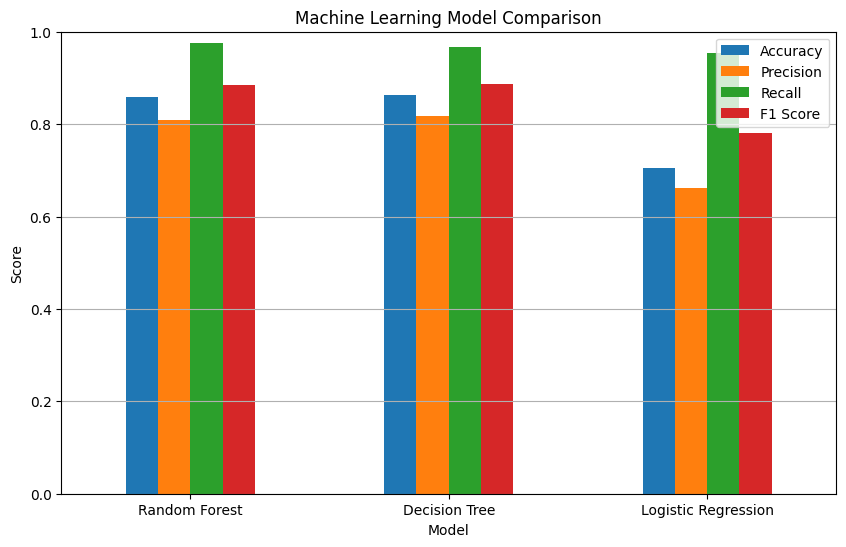

In [37]:
results_plot = results.set_index("Model")

results_plot[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y")
plt.show()

In [38]:
print(train_df["attack_cat"].value_counts())

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [39]:
attack_train = train_df[train_df["label"] == 1].copy()
attack_test = test_df[test_df["label"] == 1].copy()

print("Attack training records:", attack_train.shape)
print("Attack testing records:", attack_test.shape)

Attack training records: (119341, 36)
Attack testing records: (45332, 36)


In [40]:
X_attack_train = attack_train.drop(columns=["label", "attack_cat"])
y_attack_train = attack_train["attack_cat"]

X_attack_test = attack_test.drop(columns=["label", "attack_cat"])
y_attack_test = attack_test["attack_cat"]

print("Attack training features:", X_attack_train.shape)
print("Attack testing features:", X_attack_test.shape)

Attack training features: (119341, 34)
Attack testing features: (45332, 34)


In [41]:
X_attack_train_processed = preprocessor.transform(X_attack_train)
X_attack_test_processed = preprocessor.transform(X_attack_test)

print("Attack data preprocessing completed!")

Attack data preprocessing completed!


In [42]:
from sklearn.ensemble import RandomForestClassifier

attack_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Training attack-type model...")

attack_model.fit(
    X_attack_train_processed,
    y_attack_train
)

print("Attack-type model training completed!")

Training attack-type model...
Attack-type model training completed!


In [43]:
attack_pred = attack_model.predict(X_attack_test_processed)

print("Attack-type prediction completed!")

Attack-type prediction completed!


In [44]:
from sklearn.metrics import accuracy_score, classification_report

attack_accuracy = accuracy_score(
    y_attack_test,
    attack_pred
)

print(f"Attack Type Accuracy: {attack_accuracy * 100:.2f}%")

Attack Type Accuracy: 78.59%


In [45]:
print(classification_report(
    y_attack_test,
    attack_pred,
    zero_division=0
))

                precision    recall  f1-score   support

      Analysis       0.00      0.00      0.00       677
      Backdoor       0.03      0.05      0.04       583
           DoS       0.50      0.08      0.14      4089
      Exploits       0.59      0.87      0.71     11132
       Fuzzers       0.78      0.74      0.76      6062
       Generic       1.00      0.96      0.98     18871
Reconnaissance       0.93      0.79      0.86      3496
     Shellcode       0.44      0.32      0.37       378
         Worms       0.29      0.05      0.08        44

      accuracy                           0.79     45332
     macro avg       0.51      0.43      0.44     45332
  weighted avg       0.79      0.79      0.77     45332



In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get Random Forest feature importance
importance = rf_model.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15
print("Top 15 important features:")
display(feature_importance.head(15))

Top 15 important features:


,Feature,Importance
3,num__rate,0.090808
12,num__tcprtt,0.083712
4,num__sload,0.082892
5,num__dload,0.077608
1,num__sbytes,0.074106
14,num__ackdat,0.072785
0,num__dur,0.072123
7,num__dinpkt,0.066810
2,num__dbytes,0.065380
13,num__synack,0.061215


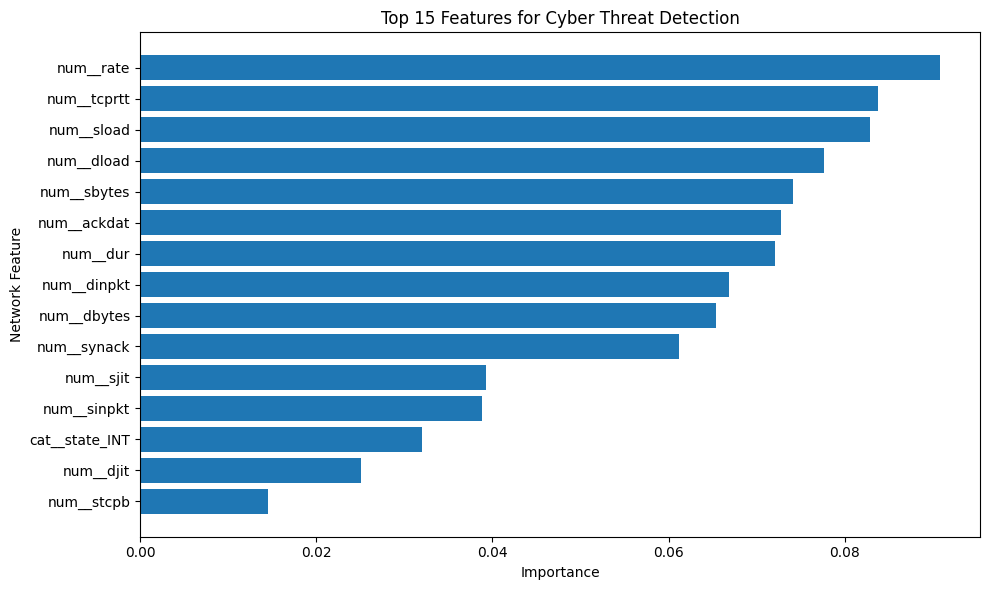

In [47]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Network Feature")
plt.title("Top 15 Features for Cyber Threat Detection")

plt.tight_layout()
plt.show()

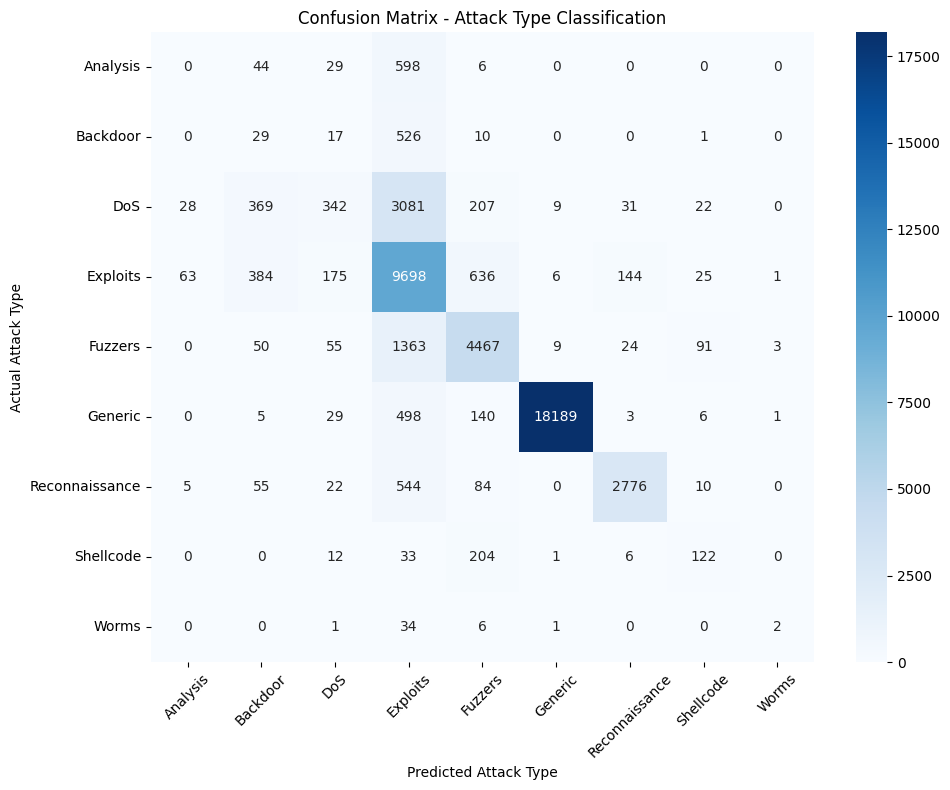

In [48]:
from sklearn.metrics import confusion_matrix

attack_labels = sorted(y_attack_test.unique())

cm_attack = confusion_matrix(
    y_attack_test,
    attack_pred,
    labels=attack_labels
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_attack,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=attack_labels,
    yticklabels=attack_labels
)

plt.xlabel("Predicted Attack Type")
plt.ylabel("Actual Attack Type")
plt.title("Confusion Matrix - Attack Type Classification")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [49]:
import joblib

joblib.dump(
    rf_model,
    "/content/cyber_threat_detection_model.pkl"
)

joblib.dump(
    attack_model,
    "/content/cyber_attack_type_model.pkl"
)

joblib.dump(
    preprocessor,
    "/content/cyber_threat_preprocessor.pkl"
)

print("All models saved successfully!")

All models saved successfully!


In [50]:
def detect_cyber_threat(input_data):

    # Convert input into DataFrame
    input_df = pd.DataFrame([input_data])

    # Preprocess
    processed_data = preprocessor.transform(input_df)

    # First prediction
    threat_prediction = rf_model.predict(processed_data)[0]

    if threat_prediction == 0:
        return {
            "status": "NORMAL",
            "message": "No cyber threat detected."
        }

    else:
        # Predict attack type
        attack_type = attack_model.predict(processed_data)[0]

        return {
            "status": "ATTACK",
            "attack_type": attack_type,
            "message": "Cyber threat detected!"
        }

In [51]:
sample = X_test.iloc[0].to_dict()

result = detect_cyber_threat(sample)

print(result)

{'status': 'ATTACK', 'attack_type': 'Shellcode', 'message': 'Cyber threat detected!'}


In [52]:
actual_label = y_test.iloc[0]
predicted_label = y_pred[0]

print("Actual:", "Attack" if actual_label == 1 else "Normal")
print("Predicted:", "Attack" if predicted_label == 1 else "Normal")

Actual: Normal
Predicted: Attack


In [53]:
import joblib

joblib.dump(rf_model, "/content/cyber_threat_detection_model.pkl")
joblib.dump(preprocessor, "/content/cyber_threat_preprocessor.pkl")

print("Files saved successfully!")

Files saved successfully!


In [54]:
from google.colab import files

files.download("/content/cyber_threat_detection_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [55]:
files.download("/content/cyber_threat_preprocessor.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>